# Bloc 2 — Notebook d'exploration des données

**Source :** `orders.json` — lignes de commande d'une enseigne de sport (2015 → 2018).

Objectif : comprendre la structure et la qualité des données **avant** d'écrire l'ETL,
puis identifier une problématique ML. Chaque constat débouche sur une **décision**
reprise dans `etl.py`, `create_db.py` ou `train.py`.

1. Structure du JSON
2. Aplatissement et types
3. Qualité : valeurs manquantes, doublons, cohérence
4. Analyse univariée
5. Analyse temporelle
6. Analyse de la cible ML (fraude)
7. Synthèse des décisions

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 40)
RAW = Path("../orders.json")

## 1. Structure du JSON

In [2]:
with RAW.open(encoding="utf-8") as f:
    records = json.load(fp=f)

print(type(records), len(records), "enregistrements")
print(json.dumps(obj=records[0], indent=2, ensure_ascii=False))

<class 'list'> 180519 enregistrements
{
  "sales": 327.75,
  "type": "DEBIT",
  "market": "Pacific Asia",
  "date order": "2018-01-31T22:56:00",
  "date shipping": "2018-02-03T22:56:00",
  "id": 77202,
  "status": "COMPLETE",
  "quantity": 1,
  "loc": {
    "country": "Indonesia",
    "state": "Java Occidental",
    "region": "Southeast Asia",
    "city": "Bekasi"
  },
  "product": {
    "name": "Smart watch ",
    "category_id": 73,
    "category_name": "Sporting Goods",
    "price": 327.75
  },
  "customer": {
    "id": 20755,
    "firstname": "Cally",
    "lastname": "Holloway",
    "loc": {
      "country": "Puerto Rico",
      "state": "PR",
      "city": "Caguas",
      "zipcode": 725.0,
      "street": "5365 Noble Nectar Island"
    }
  }
}


**Constats :** une liste d'objets ; chaque objet est une **ligne de commande** (un produit)
avec trois objets imbriqués : `loc` (lieu de livraison), `product`, `customer` (lui-même
avec `customer.loc`). → il faudra **aplatir** puis **normaliser** en tables.

In [3]:
# Toutes les clés sont-elles présentes partout ?
def keys(d, prefix=""):
    for k, v in d.items():
        yield from keys(d=v, prefix=f"{prefix}{k}.") if isinstance(v, dict) else [prefix + k]

from collections import Counter
key_counts = Counter(k for r in records for k in keys(d=r))
pd.Series(data=key_counts).sort_values().head(n=5)

order zipcode            24840
customer.lastname       180511
customer.loc.zipcode    180516
sales                   180519
date shipping           180519
dtype: int64

→ `order zipcode` n'existe que dans ~14 % des lignes, `customer.lastname` et
`customer.loc.zipcode` manquent ponctuellement.

## 2. Aplatissement et types

In [4]:
df = pd.json_normalize(data=records)
print(df.shape)
df.head()

(180519, 25)


,sales,type,market,date order,date shipping,id,status,quantity,loc.country,loc.state,loc.region,loc.city,product.name,product.category_id,product.category_name,product.price,customer.id,customer.firstname,customer.lastname,customer.loc.country,customer.loc.state,customer.loc.city,customer.loc.zipcode,customer.loc.street,order zipcode
0,327.75,DEBIT,Pacific Asia,2018-01-31T22:56:00,2018-02-03T22:56:00,77202,COMPLETE,1,Indonesia,Java Occidental,Southeast Asia,Bekasi,Smart watch,73,Sporting Goods,327.75,20755,Cally,Holloway,Puerto Rico,PR,Caguas,725.0,5365 Noble Nectar Island,NaN
1,327.75,TRANSFER,Pacific Asia,2018-01-13T12:27:00,2018-01-18T12:27:00,75939,PENDING,1,India,Rajastán,South Asia,Bikaner,Smart watch,73,Sporting Goods,327.75,19492,Irene,Luna,Puerto Rico,PR,Caguas,725.0,2679 Rustic Loop,NaN
2,327.75,CASH,Pacific Asia,2018-01-13T12:06:00,2018-01-17T12:06:00,75938,CLOSED,1,India,Rajastán,South Asia,Bikaner,Smart watch,73,Sporting Goods,327.75,19491,Gillian,Maldonado,EE. UU.,CA,San Jose,95125.0,8510 Round Bear Gate,NaN
3,327.75,DEBIT,Pacific Asia,2018-01-13T11:45:00,2018-01-16T11:45:00,75937,COMPLETE,1,Australia,Queensland,Oceania,Townsville,Smart watch,73,Sporting Goods,327.75,19490,Tana,Tate,EE. UU.,CA,Los Angeles,90027.0,3200 Amber Bend,NaN
4,327.75,PAYMENT,Pacific Asia,2018-01-13T11:24:00,2018-01-15T11:24:00,75936,PENDING_PAYMENT,1,Australia,Queensland,Oceania,Townsville,Smart watch,73,Sporting Goods,327.75,19489,Orli,Hendricks,Puerto Rico,PR,Caguas,725.0,8671 Iron Anchor Corners,NaN


In [5]:
df.dtypes

sales                    float64
type                         str
market                       str
date order                   str
date shipping                str
id                         int64
status                       str
quantity                   int64
loc.country                  str
loc.state                    str
loc.region                   str
loc.city                     str
product.name                 str
product.category_id        int64
product.category_name        str
product.price            float64
customer.id                int64
customer.firstname           str
customer.lastname            str
customer.loc.country         str
customer.loc.state           str
customer.loc.city            str
customer.loc.zipcode     float64
customer.loc.street          str
order zipcode            float64
dtype: object

In [ ]:
df["date order"] = pd.to_datetime(arg=df["date order"])
df["date shipping"] = pd.to_datetime(arg=df["date shipping"])
#df['date'] = pd.to_datetime(df['date'], format='%d/%m/%Y', errors='coerce')
df.describe()

,sales,date order,date shipping,id,quantity,product.category_id,product.price,customer.id,customer.loc.zipcode,order zipcode
count,180519.000000,180519,180519,180519.000000,180519.000000,180519.000000,180519.000000,180519.000000,180516.000000,24840.000000
mean,203.772096,2016-06-12 17:47:04.669868,2016-06-16 05:45:23.202433,36221.894903,2.127638,31.851451,141.232550,6691.379495,35921.126914,55426.132327
min,9.990000,2015-01-01 00:00:00,2015-01-03 00:00:00,1.000000,1.000000,2.000000,9.990000,1.000000,603.000000,1040.000000
25%,119.980003,2015-09-21 13:49:00,2015-09-25 06:59:00,18057.000000,1.000000,18.000000,50.000000,3258.500000,725.000000,23464.000000
50%,199.919998,2016-06-11 13:06:00,2016-06-15 08:32:00,36140.000000,1.000000,29.000000,59.990002,6457.000000,19380.000000,59405.000000
75%,299.950012,2017-03-01 08:42:00,2017-03-04 21:29:00,54144.000000,3.000000,45.000000,199.990005,9779.000000,78207.000000,90008.000000
max,1999.989990,2018-01-31 23:38:00,2018-02-06 22:14:00,77204.000000,5.000000,76.000000,1999.989990,20757.000000,99205.000000,99301.000000
std,132.273077,NaN,NaN,21045.379569,1.453451,15.640064,139.732492,4162.918106,37542.461122,31919.279101


**Constats :** les dates sont des chaînes ISO → conversion en `datetime`.
Le code postal client est un `float` (`725.0`) → à convertir en texte (`00725`).

## 3. Qualité des données

### 3.1 Valeurs manquantes

In [7]:
missing = pd.DataFrame(data={"nb manquants": df.isna().sum(), "% manquant": df.isna().mean().mul(other=100).round(decimals=3)})
missing[missing["nb manquants"] > 0].sort_values(by="nb manquants", ascending=False)

,nb manquants,% manquant
order zipcode,155679,86.240
customer.lastname,8,0.004
customer.loc.zipcode,3,0.002


**Décisions :**
- `order zipcode` (~86 % manquant) → **colonne supprimée** (imputation non pertinente).
- `customer.lastname` (8 lignes) → imputé par `"Inconnu"` (le client reste identifiable par son id).
- `customer.loc.zipcode` (3 lignes) → laissé à `NULL`.

### 3.2 Doublons et granularité

In [8]:
print("Lignes                 :", len(df))
print("Doublons stricts       :", df.duplicated().sum())
print("Commandes distinctes   :", df["id"].nunique())
print("Clients distincts      :", df["customer.id"].nunique())
print("Produits distincts     :", df["product.name"].nunique())
print("Catégories distinctes  :", df["product.category_id"].nunique())

Lignes                 : 180519
Doublons stricts       : 11370
Commandes distinctes   : 65752
Clients distincts      : 20652
Produits distincts     : 118
Catégories distinctes  : 51


**Constats :** `id` n'est **pas unique** : c'est l'identifiant de la commande, partagé par
plusieurs lignes. Les ~11 000 doublons stricts n'ont pas de clé de ligne pour les distinguer
→ **supprimés**. Cela justifie un modèle `orders` (en-tête) + `order_items` (lignes).

### 3.3 Cohérence

In [ ]:
# Colonnes numériques
df_num = df.select_dtypes(include='number')        # int + float
df_int = df.select_dtypes(include='int')           # entiers seulement
df_float = df.select_dtypes(include='float')       # flottants

# Colonnes texte
df_text = df.select_dtypes(include='object')        # object (souvent str)
df_str = df.select_dtypes(include='string')         # dtype StringDtype

# Dates / temporaires
df_dates = df.select_dtypes(include='datetime')
df_dates = df.select_dtypes(include=['datetime64[ns]', 'timedelta64[ns]'])

# Catégorielles
df_cat = df.select_dtypes(include='category')

In [30]:
for (type, group)in df.groupby('type') :
    print(f"{type} shape={group.shape}")

CASH shape=(19616, 25)
DEBIT shape=(69295, 25)
PAYMENT shape=(41725, 25)
TRANSFER shape=(49883, 25)


In [32]:
df.groupby('type')['status'].describe().unstack()

        type    
count   CASH                  19616
        DEBIT                 69295
        PAYMENT               41725
        TRANSFER              49883
unique  CASH                      1
        DEBIT                     2
        PAYMENT                   2
        TRANSFER                  4
top     CASH                 CLOSED
        DEBIT              COMPLETE
        PAYMENT     PENDING_PAYMENT
        TRANSFER         PROCESSING
freq    CASH                  19616
        DEBIT                 59491
        PAYMENT               39832
        TRANSFER              21902
dtype: object

In [33]:
df.groupby('type')['status'].describe()

,count,unique,top,freq
type,,,,
CASH,19616,1,CLOSED,19616
DEBIT,69295,2,COMPLETE,59491
PAYMENT,41725,2,PENDING_PAYMENT,39832
TRANSFER,49883,4,PROCESSING,21902


In [18]:
df.dropna(subset=['customer.lastname']).shape

(180511, 25)

In [11]:
df.head()

,sales,type,market,date order,date shipping,id,status,quantity,loc.country,loc.state,loc.region,loc.city,product.name,product.category_id,product.category_name,product.price,customer.id,customer.firstname,customer.lastname,customer.loc.country,customer.loc.state,customer.loc.city,customer.loc.zipcode,customer.loc.street,order zipcode
0,327.75,DEBIT,Pacific Asia,2018-01-31 22:56:00,2018-02-03 22:56:00,77202,COMPLETE,1,Indonesia,Java Occidental,Southeast Asia,Bekasi,Smart watch,73,Sporting Goods,327.75,20755,Cally,Holloway,Puerto Rico,PR,Caguas,725.0,5365 Noble Nectar Island,NaN
1,327.75,TRANSFER,Pacific Asia,2018-01-13 12:27:00,2018-01-18 12:27:00,75939,PENDING,1,India,Rajastán,South Asia,Bikaner,Smart watch,73,Sporting Goods,327.75,19492,Irene,Luna,Puerto Rico,PR,Caguas,725.0,2679 Rustic Loop,NaN
2,327.75,CASH,Pacific Asia,2018-01-13 12:06:00,2018-01-17 12:06:00,75938,CLOSED,1,India,Rajastán,South Asia,Bikaner,Smart watch,73,Sporting Goods,327.75,19491,Gillian,Maldonado,EE. UU.,CA,San Jose,95125.0,8510 Round Bear Gate,NaN
3,327.75,DEBIT,Pacific Asia,2018-01-13 11:45:00,2018-01-16 11:45:00,75937,COMPLETE,1,Australia,Queensland,Oceania,Townsville,Smart watch,73,Sporting Goods,327.75,19490,Tana,Tate,EE. UU.,CA,Los Angeles,90027.0,3200 Amber Bend,NaN
4,327.75,PAYMENT,Pacific Asia,2018-01-13 11:24:00,2018-01-15 11:24:00,75936,PENDING_PAYMENT,1,Australia,Queensland,Oceania,Townsville,Smart watch,73,Sporting Goods,327.75,19489,Orli,Hendricks,Puerto Rico,PR,Caguas,725.0,8671 Iron Anchor Corners,NaN


In [9]:
# Les attributs d'en-tête sont-ils constants au sein d'une commande ?
header_cols = ["customer.id", "date order", "date shipping", "status", "type", "market", "loc.city"]
(df.groupby(by="id")[header_cols].nunique() > 1).sum()

customer.id      0
date order       0
date shipping    0
status           0
type             0
market           0
loc.city         0
dtype: int64

In [10]:
# sales = quantité x prix ?  expédition après commande ?  un prix par produit ?
ecart = (df["sales"] - df["quantity"] * df["product.price"]).abs()
print("Lignes où sales != qty x prix :", (ecart > 0.01).sum())
print("Expéditions avant commande    :", (df["date shipping"] < df["date order"]).sum())
print("Produits avec plusieurs prix  :", (df.groupby(by="product.name")["product.price"].nunique() > 1).sum())
print("Noms avec espaces parasites   :", (df["product.name"] != df["product.name"].str.strip()).sum())

Lignes où sales != qty x prix : 0
Expéditions avant commande    : 0
Produits avec plusieurs prix  : 0
Noms avec espaces parasites   : 1774


**Constats :** les données sont cohérentes (en-têtes constants, montants exacts, prix
uniques par produit) → ces règles sont tout de même **codées dans l'ETL** (`validate()`)
pour protéger les futurs chargements. Les espaces en fin de nom (`"Smart watch "`) sont
supprimés.

## 4. Analyse univariée

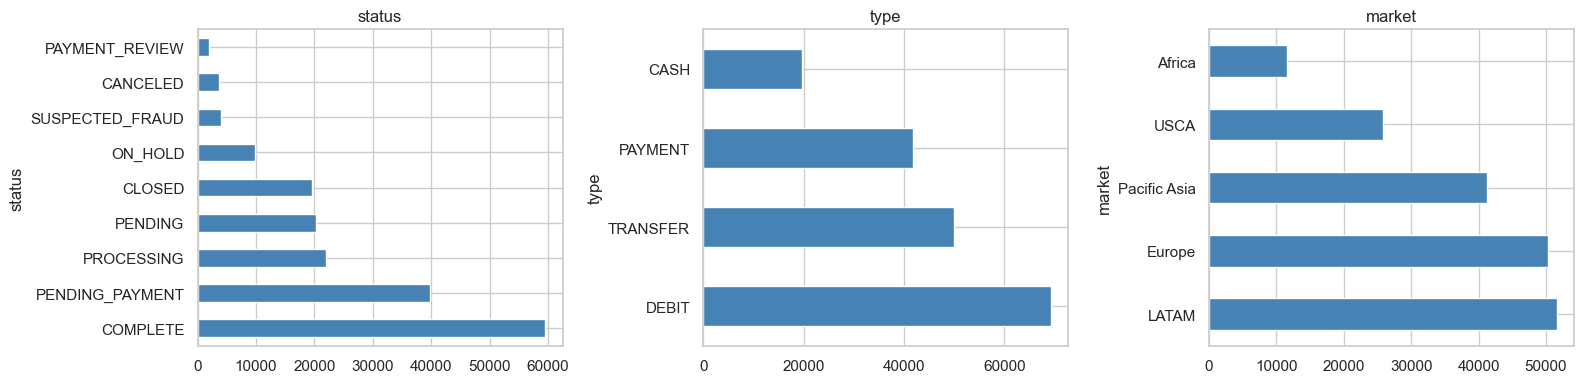

In [11]:
fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(16, 4))
for ax, col in zip(axes, ["status", "type", "market"]):
    df[col].value_counts().plot.barh(ax=ax, color="steelblue")
    ax.set_title(label=col)
plt.tight_layout()

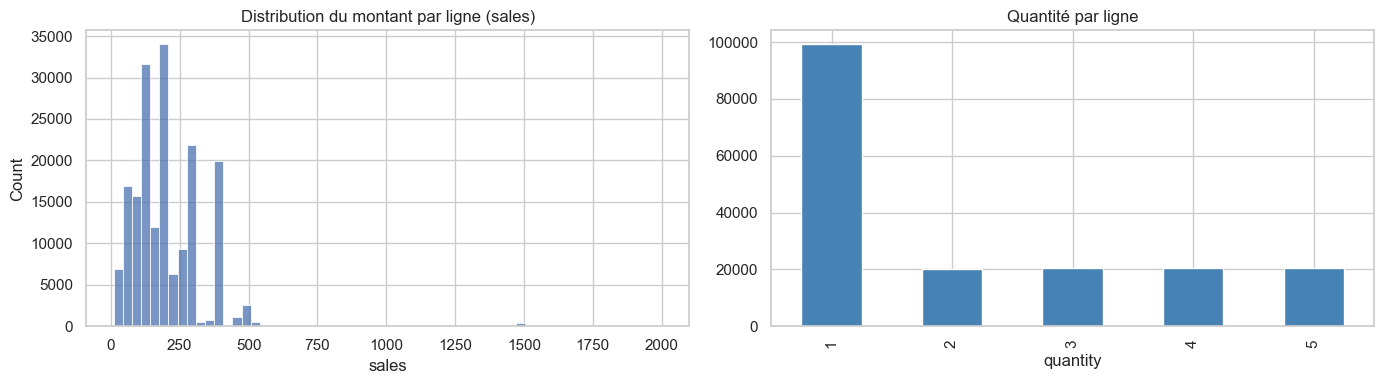

In [12]:
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(14, 4))
sns.histplot(data=df["sales"], bins=60, ax=axes[0])
axes[0].set_title(label="Distribution du montant par ligne (sales)")
df["quantity"].value_counts().sort_index().plot.bar(ax=axes[1], color="steelblue")
axes[1].set_title(label="Quantité par ligne")
plt.tight_layout()

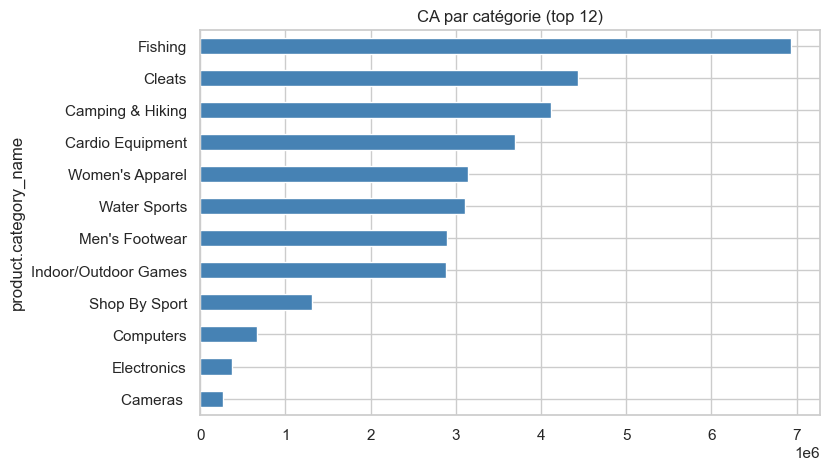

In [13]:
top_cat = df.groupby(by="product.category_name")["sales"].sum().sort_values().tail(n=12)
top_cat.plot.barh(figsize=(8, 5), color="steelblue", title="CA par catégorie (top 12)");

In [14]:
df["customer.loc.country"].value_counts()

customer.loc.country
EE. UU.        111146
Puerto Rico     69373
Name: count, dtype: int64

**Constats :** distribution des montants très asymétrique (quelques produits chers) ;
plus de la moitié des lignes ont une quantité de 1. Les clients sont tous aux
États-Unis / Porto Rico alors que les livraisons couvrent 5 marchés → adresse client
et lieu de livraison sont **deux notions distinctes** (colonnes séparées en base).

## 5. Analyse temporelle

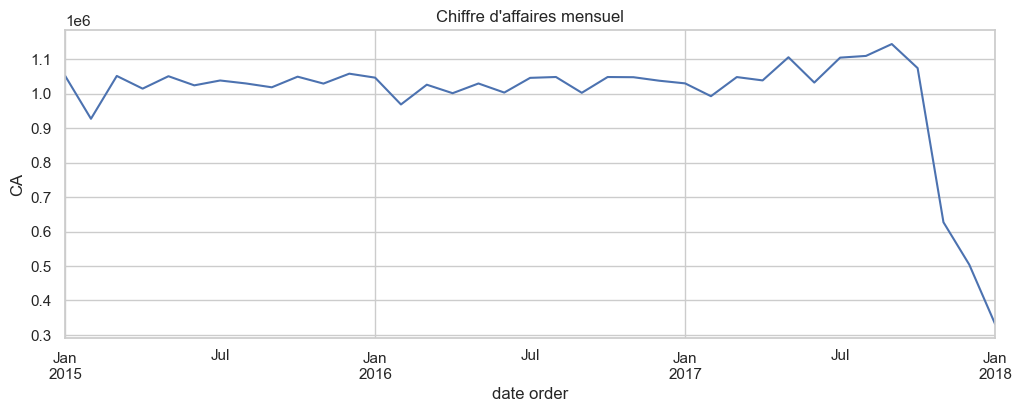

In [15]:
monthly = df.set_index(keys="date order")["sales"].resample(rule="MS").sum()
ax = monthly.plot(figsize=(12, 4), title="Chiffre d'affaires mensuel")
ax.set_ylabel(ylabel="CA");

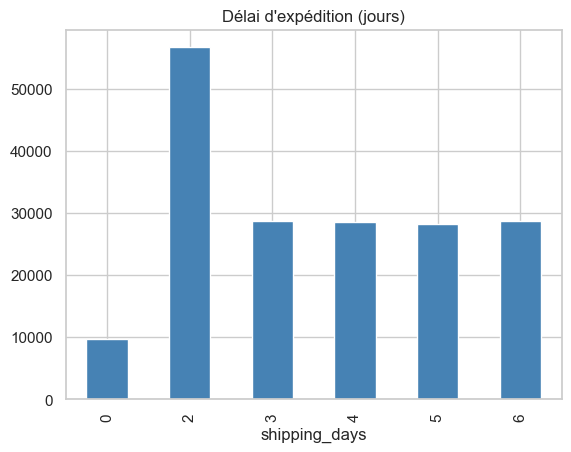

In [16]:
df["shipping_days"] = (df["date shipping"] - df["date order"]).dt.days
df["shipping_days"].value_counts().sort_index().plot.bar(color="steelblue", title="Délai d'expédition (jours)");

**Constats :** activité stable de 2015 à fin 2017 ; **janvier 2018 seulement partiel** et
avec un niveau différent → à garder en tête pour le découpage train/test temporel.

## 6. Problématique ML : détection de fraude

Le statut `SUSPECTED_FRAUD` permet de poser un problème de **classification binaire** :
*peut-on signaler une commande suspecte au moment où elle est passée ?*
On travaille **au niveau commande** (une ligne = une commande).

In [17]:
orders = df.drop_duplicates().groupby(by="id").agg(
    payment_type=("type", "first"),
    market=("market", "first"),
    status=("status", "first"),
    order_date=("date order", "first"),
    total_sales=("sales", "sum"),
    n_items=("product.name", "size"),
)
orders["is_fraud"] = (orders["status"] == "SUSPECTED_FRAUD").astype(dtype=int)
print(f"Taux de fraude : {orders['is_fraud'].mean():.2%} sur {len(orders)} commandes")

Taux de fraude : 2.26% sur 65752 commandes


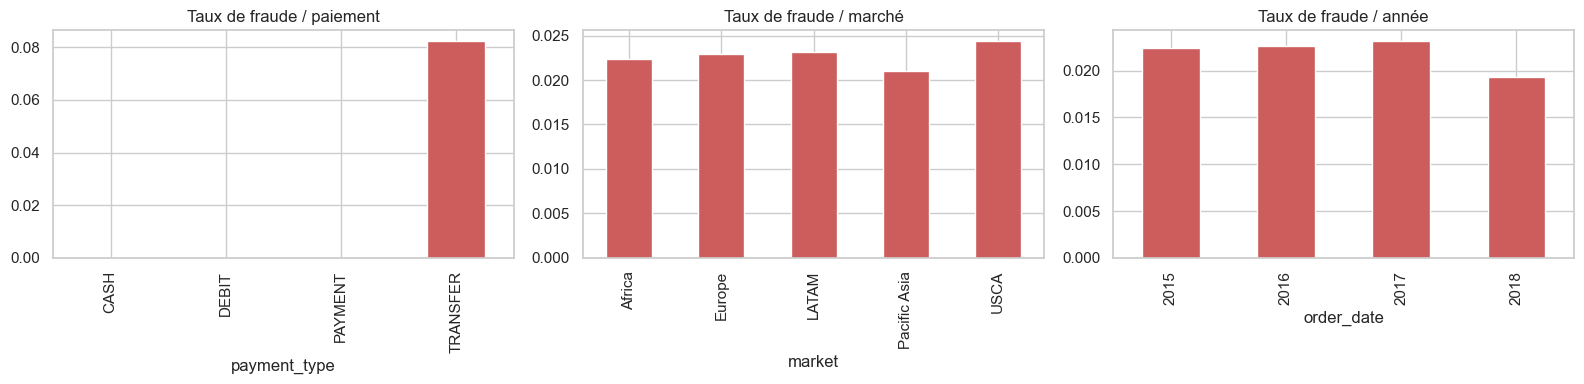

In [18]:
fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(16, 4))
orders.groupby(by="payment_type")["is_fraud"].mean().plot.bar(ax=axes[0], color="indianred", title="Taux de fraude / paiement")
orders.groupby(by="market")["is_fraud"].mean().plot.bar(ax=axes[1], color="indianred", title="Taux de fraude / marché")
orders.groupby(by=orders["order_date"].dt.year)["is_fraud"].mean().plot.bar(ax=axes[2], color="indianred", title="Taux de fraude / année")
plt.tight_layout()

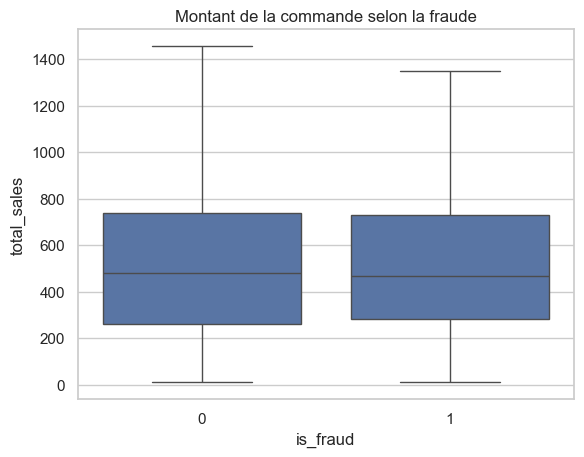

In [19]:
sns.boxplot(data=orders, x="is_fraud", y="total_sales", showfliers=False)
plt.title(label="Montant de la commande selon la fraude");

**Constats clés :**
- Classe **très déséquilibrée** (~2 %) → l'accuracy est trompeuse ; on utilisera
  **PR-AUC / rappel** et `class_weight="balanced"`.
- La fraude n'apparaît **que sur les paiements `TRANSFER`** (~8 % d'entre eux). Les autres
  variables (marché, montant, année) varient très peu → on s'attend à un modèle qui
  apprend surtout cette règle. C'est une limite du jeu de données, à documenter.
- Le **statut** sert à construire la cible : il ne doit jamais être une feature (fuite).
  Idem pour la date d'expédition, inconnue au moment de la commande.

## 7. Synthèse des décisions

| Constat | Décision | Où |
|---|---|---|
| JSON imbriqué | `pd.json_normalize` + renommage snake_case | `etl.py` |
| `order zipcode` 86 % manquant | colonne supprimée | `etl.py` |
| `lastname` / `zipcode` manquants (rares) | `"Inconnu"` / `NULL`, zipcode en texte | `etl.py` |
| 11 370 doublons stricts | suppression | `etl.py` |
| Espaces parasites | `str.strip()` | `etl.py` |
| `id` = commande, pas ligne | tables `orders` + `order_items` | `create_db.py` |
| Clients / produits / catégories répétés | tables dédiées (3FN) | `create_db.py` |
| Adresse client ≠ lieu de livraison | colonnes séparées | `create_db.py` |
| Fraude rare (2 %) et liée à `TRANSFER` | PR-AUC, `class_weight`, baseline Dummy | `train.py` |
| Évolution dans le temps, 2018 partiel | découpage train/test temporel | `train.py` |